In [5]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool

import requests
import random

In [6]:
load_dotenv()

True

In [7]:
llm = ChatOpenAI(model='gpt-4o')

In [8]:
# Tools
search_tool = DuckDuckGoSearchRun(region="us-en")

@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}
        
        return {"first_num": first_num, "second_num": second_num, "operation": operation, "result": result}
    except Exception as e:
        return {"error": str(e)}


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=C9PE94QUEW9VWGFM"
    r = requests.get(url)
    return r.json()


In [9]:
# Make tool list
tools = [get_stock_price, search_tool, calculator]

# Make the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [10]:
# state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [11]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [12]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

In [13]:
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")    

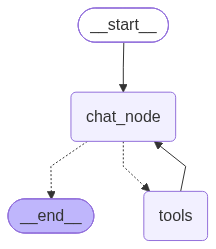

In [14]:
chatbot = graph.compile()

chatbot

In [15]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)


Hi there! How can I assist you today?


In [16]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is 2*3?")]})
print(out["messages"][-1].content)

The result of \(2 \times 3\) is 6.


In [17]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is the stock price of apple")]})
print(out["messages"][-1].content)

The latest stock price of Apple (AAPL) is $344.63. The price changed by -$4.28, which is a decrease of -1.23% from the previous close.


In [18]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]})
print(out["messages"][-1].content)

The current stock price of Apple (AAPL) is $344.63. To purchase 50 shares, it will cost you $17,231.50.


In [20]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.types import Command


class State(TypedDict):
    messages: Annotated[list, add_messages]


def waiter(state: State) -> Command:
    print("Waiter: order le liya")
    return Command(goto="chef", update={"messages": [("assistant", "Order: 1 pizza")]})


def chef(state: State) -> Command:
    print("Chef: pizza bana diya")
    return Command(goto="cashier", update={"messages": [("assistant", "Pizza ready")]})


def cashier(state: State) -> Command:
    print("Cashier: bill 300 Rs")
    return Command(goto="__end__", update={"messages": [("assistant", "Bill: 300 Rs")]})


builder = StateGraph(State)
builder.add_node("waiter", waiter)
builder.add_node("chef", chef)
builder.add_node("cashier", cashier)
builder.add_edge(START, "waiter")  # sirf start fix hai, baaki sab handoff


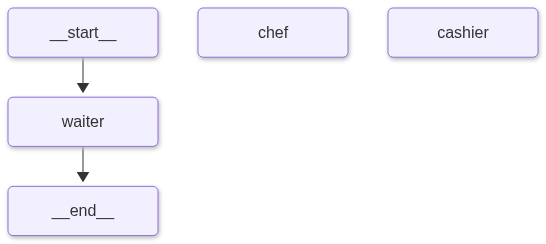

In [21]:
graph = builder.compile()

graph

In [22]:
result = graph.invoke({"messages": [("user", "Ek pizza aur bill")]})

Waiter: order le liya
Chef: pizza bana diya
Cashier: bill 300 Rs
